[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/04-machine-learning/notebooks/01-first-model-regression.ipynb)

# 04-01 · Your first model: linear regression on the diabetes data

**Goal:** go through the whole machine learning workflow once, slowly: load data → look at it → split → baseline → train → measure → interpret.

**Words used here** (full explanations in `concepts.md`):
- **feature** — an input column; **label** (target) — the column we want to predict.
- **regression** — predicting a number.
- **train/test split** — hiding some rows so we can test the model fairly.

Runs in a few seconds on any laptop or on Google Colab. No internet needed: the dataset ships inside scikit-learn.

## Step 1 · Import the tools

- `numpy` and `pandas` for tables of numbers, `matplotlib` for charts.
- From scikit-learn (`sklearn`) we import a dataset loader, the split function, two models and some metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import sklearn
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


## Step 2 · Load the data

`return_X_y=True` gives us the features `X` and the label `y` separately. `as_frame=True` makes them pandas objects so they print nicely.

The dataset: 442 diabetes patients. 10 features (age, sex, body-mass index `bmi`, blood pressure `bp`, six blood measurements `s1`–`s6`). The label is a number measuring how much the disease progressed one year later. Note: the features have already been **scaled** (centred around 0) by the dataset authors, which is why age looks like 0.038 rather than 59.

In [2]:
X, y = load_diabetes(return_X_y=True, as_frame=True)
print("X shape:", X.shape, " -> rows, columns")
print("y shape:", y.shape)
X.head()

X shape: (442, 10)  -> rows, columns
y shape: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## Step 3 · Look at the data before modelling

Always check: how big are the label values, are there missing values, which features seem related to the label? `.describe()` gives summary statistics. `.corr()` gives the **correlation** (a number from -1 to 1 saying how strongly two columns move together).

In [3]:
print(y.describe().round(1))
print("\nMissing values in X:", int(X.isna().sum().sum()))
print("\nCorrelation of each feature with the label:")
print(X.corrwith(y).sort_values(ascending=False).round(2))

count    442.0
mean     152.1
std       77.1
min       25.0
25%       87.0
50%      140.5
75%      211.5
max      346.0
Name: target, dtype: float64

Missing values in X: 0

Correlation of each feature with the label:
bmi    0.59
s5     0.57
bp     0.44
s4     0.43
s6     0.38
s1     0.21
age    0.19
s2     0.17
sex    0.04
s3    -0.39
dtype: float64


`bmi` (body-mass index) and `s5` have the strongest link to the label. Let us see `bmi` on a chart: each dot is one patient.

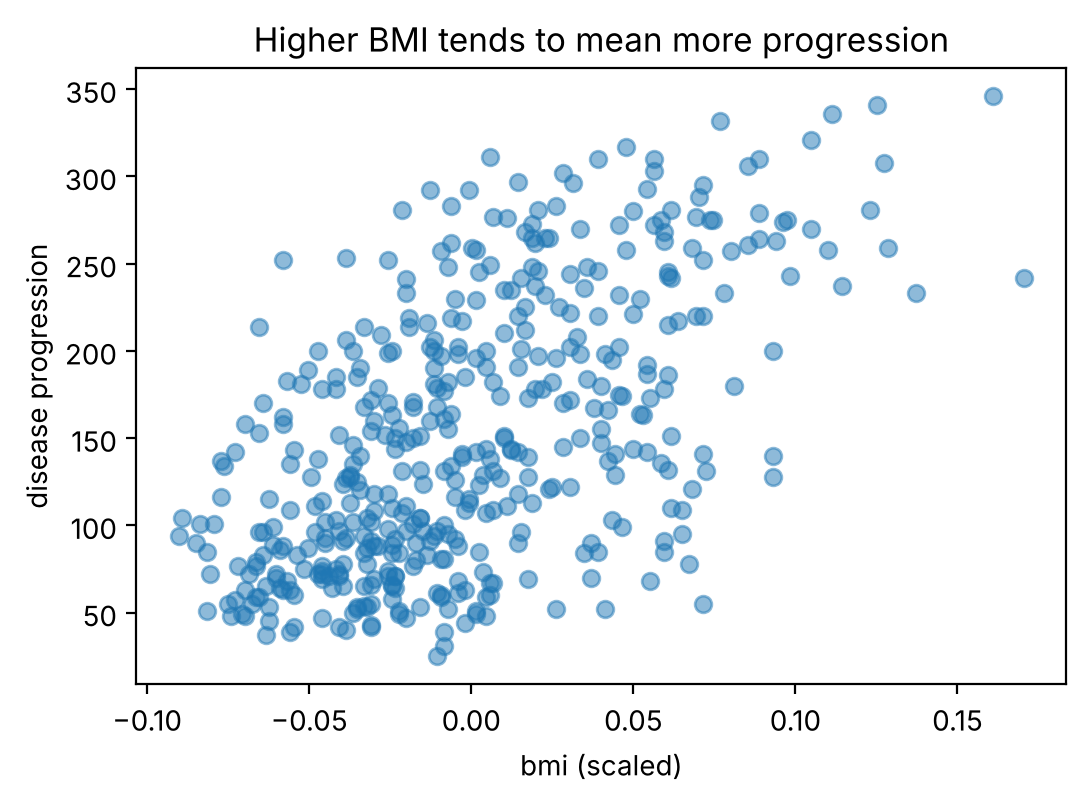

In [4]:
plt.figure(figsize=(6, 4))
plt.scatter(X["bmi"], y, alpha=0.5)
plt.xlabel("bmi (scaled)")
plt.ylabel("disease progression")
plt.title("Higher BMI tends to mean more progression")
plt.show()

## Step 4 · Split into training and test sets

We hide 20% of the patients as a test set. The model never sees them during training. `random_state=42` makes the random split repeatable.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("training rows:", len(X_train), "  test rows:", len(X_test))

training rows: 353   test rows: 89


## Step 5 · A baseline: the laziest possible model

A **baseline** is a very simple model that tells us what "no skill" looks like. `DummyRegressor` always predicts the average of the training labels, whatever the input. Any real model must beat this.

In [6]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)
print("baseline always predicts:", round(base_pred[0], 1))
print("baseline MAE:", round(mean_absolute_error(y_test, base_pred), 1))

baseline always predicts: 153.7
baseline MAE: 64.0


## Step 6 · Train a linear regression

The three-step pattern you will use with every scikit-learn model:
1. create it, 2. `.fit()` on training data, 3. `.predict()` on new data.

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("first five predictions:", pred[:5].round(1))
print("first five true values:", y_test.values[:5])

first five predictions: [139.5 179.5 134.  291.4 123.8]
first five true values: [219.  70. 202. 230. 111.]


## Step 7 · Measure the errors — first by hand, then with scikit-learn

Doing it by hand once shows there is no magic:
- **MAE** = average of |true − predicted|
- **MSE** = average of (true − predicted)²
- **RMSE** = square root of MSE (back in the label's units)
- **R²** = 1 − (model's squared error ÷ squared error of always guessing the average)

In [8]:
errors = y_test.values - pred
mae_hand = np.mean(np.abs(errors))
mse_hand = np.mean(errors ** 2)
rmse_hand = np.sqrt(mse_hand)
r2_hand = 1 - np.sum(errors ** 2) / np.sum((y_test.values - y_test.mean()) ** 2)

print(f"By hand      MAE={mae_hand:.2f}  RMSE={rmse_hand:.2f}  R2={r2_hand:.3f}")
print(f"scikit-learn MAE={mean_absolute_error(y_test, pred):.2f}  "
      f"RMSE={np.sqrt(mean_squared_error(y_test, pred)):.2f}  R2={r2_score(y_test, pred):.3f}")

By hand      MAE=42.79  RMSE=53.85  R2=0.453
scikit-learn MAE=42.79  RMSE=53.85  R2=0.453


**How to read this:** on average we are about 43 units off, against about 64 for the baseline. R² ≈ 0.45 means the model explains about 45% of the variation between patients. Medical data is noisy, so this is a normal, honest result — do not expect 99% on real-world regression.

## Step 8 · Picture the predictions

If the model were perfect, every dot would sit on the dashed diagonal line.

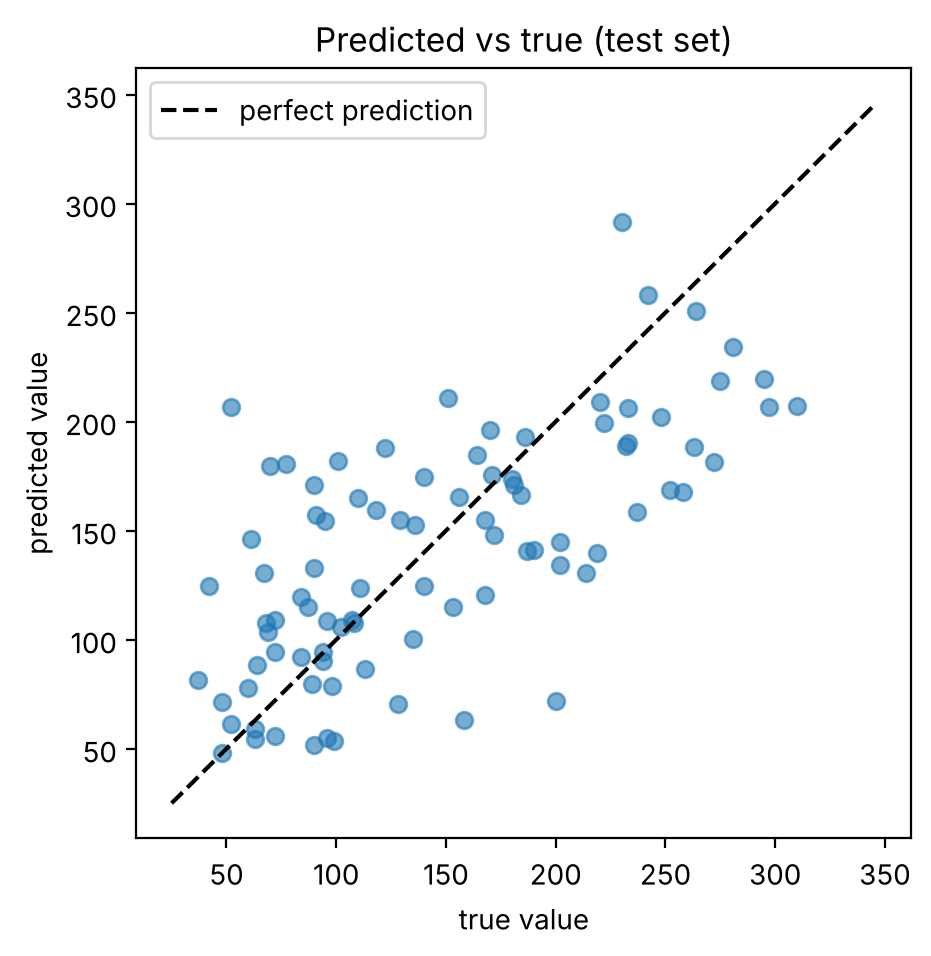

In [9]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, alpha=0.6)
lims = [y.min(), y.max()]
plt.plot(lims, lims, "k--", label="perfect prediction")
plt.xlabel("true value"); plt.ylabel("predicted value")
plt.title("Predicted vs true (test set)")
plt.legend(); plt.show()

## Step 9 · Look inside the model

Linear regression learned one **weight** (coefficient) per feature plus an **intercept**. A positive weight means "when this feature goes up, the prediction goes up". Because these features were pre-scaled to similar ranges, we can roughly compare the sizes of the weights.

intercept: 151.3


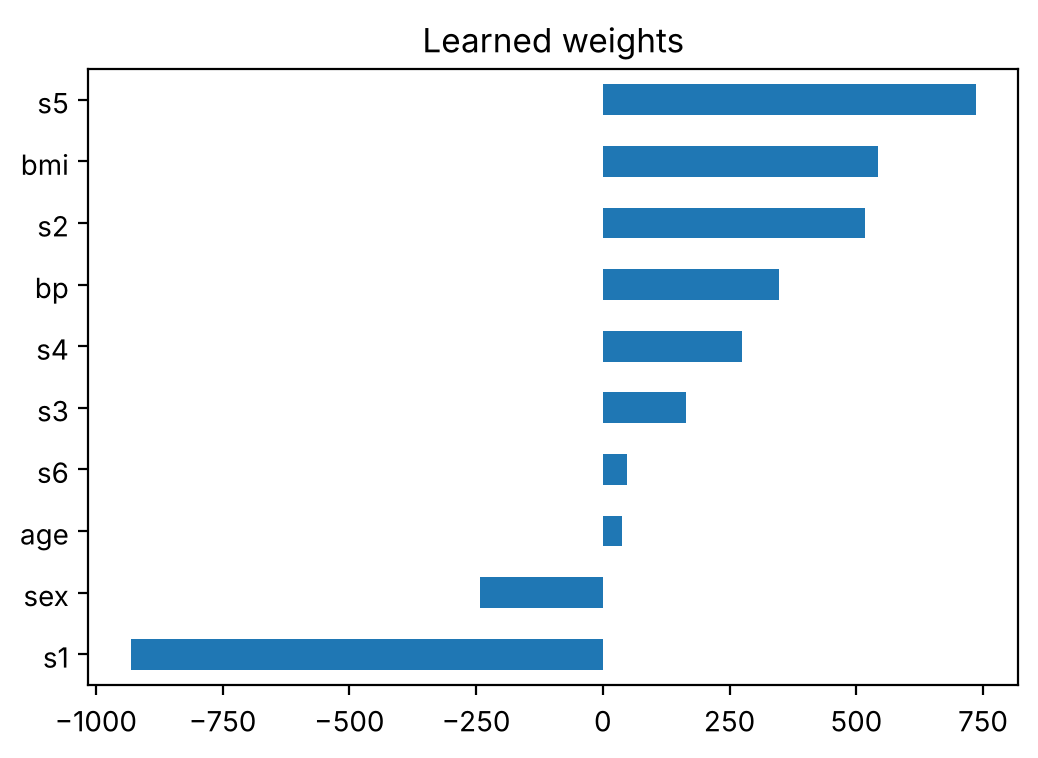

In [10]:
weights = pd.Series(model.coef_, index=X.columns).sort_values()
print("intercept:", round(model.intercept_, 1))
weights.plot.barh(figsize=(6, 4), title="Learned weights")
plt.show()

## Step 10 · Predict for a brand-new patient

A trained model is a function. Give it one new row with the same 10 columns and it returns a number. Here we invent a patient by copying one test row and raising their BMI.

In [11]:
new_patient = X_test.iloc[[0]].copy()
print("original prediction:", model.predict(new_patient).round(1))
new_patient["bmi"] += 0.05
print("with higher bmi:    ", model.predict(new_patient).round(1))

original prediction: [139.5]
with higher bmi:     [166.7]


## Recap

- You loaded data, explored it, split it, built a baseline and a real model.
- You computed MAE, RMSE and R² by hand and matched scikit-learn.
- Always compare with a baseline, and always measure on the test set.

**Try it:** replace `LinearRegression()` with `from sklearn.linear_model import Ridge` and `Ridge(alpha=1.0)`. Does the test MAE change?